# ДЗ 3. Ошибки и устойчивость E3

LightGBM E3 показала средний ROC-AUC **0,958076** в ДЗ 2. За этим результатом скрывается заметный разрыв между личными и деловыми поездками. Разберём его и проверим, как качество меняется при новом разбиении и сокращении обучающей выборки. [ДЗ 2](02_model_and_ablation.ipynb)

## Данные и протокол

| Что фиксируем | Как считаем |
|---|---|
| Модель | LightGBM на 21 исходном признаке и произведении оценок кресла и развлечений |
| Выбор E3 | Максимальный средний ROC-AUC в ДЗ 2. Разница с E1 составила 0,000037 на тех же фолдах |
| Данные | 699 635 строк конкурсного `train.csv`. Исходное разбиение: 5 стратифицированных фолдов, seed 42 |
| Метрика | Средний ROC-AUC по фолдам. Для ошибок используем порог 0,5 |
| Контроль утечек | Каждую строку оценивает модель, для которой эта строка была проверочной. Предобработку настраиваем только на обучающих строках |

Скрипт сверяет хеш данных, состав фолдов, ID, метки и метрики с ДЗ 2. Тестовую выборку и таблицу лидеров для выбора настроек не использовали. Для проверки преимущества E3 нужны независимые данные. [Таблица опытов ДЗ 2](../reports/hw2/summary.csv) · [Настройки LightGBM](../configs/hw2.yaml)

In [1]:
from itertools import count
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

root = Path.cwd()
if not (root / "reports/hw3").is_dir():
    root = root.parent
report = root / "reports/hw3"
table_ids = count(1)

def read(name):
    return pd.read_csv(report / f"{name}.csv")

def show(table, formats=None):
    styled = table.style.hide(axis="index").set_uuid(f"hw3_{next(table_ids)}")
    text_columns = table.select_dtypes(include=["object", "string"]).columns
    styled = styled.set_properties(subset=text_columns, **{"text-align": "left"})
    display(styled.format(formats or {}, decimal=",", thousands=" "))

def integer(value):
    return f"{int(value):,}".replace(",", " ")

def fraction(n, total):
    return f"{integer(n)} / {integer(total)}"

def share(n, total):
    percent = f"{n / total:.1%}".replace(".", ",")
    return f"{percent} ({fraction(n, total)})"

## Где ошибается модель

При пороге 0,5 получаем **52 282 ошибки**. Сводка показывает число и долю от всех ошибок. FP означает ложный прогноз удовлетворённости, FN означает пропуск положительного ответа. Калибровку оценок модели не проверяли.

In [2]:
counts = read("error_counts")
counts["Записей"] = [
    f"{integer(n)} ({p:.1%})".replace(".", ",")
    for n, p in zip(counts.n, counts.share_of_errors)
]
bands = ["Около порога", "Между диапазонами", "Край шкалы"]
by_band = counts.pivot(index="band", columns="kind", values="Записей").loc[bands, ["FP", "FN"]]
by_band["Оценка модели"] = ["[0,4; 0,6)", "Остальные", "≤ 0,1 или ≥ 0,9"]
show(by_band.reset_index(names="Диапазон")[["Диапазон", "Оценка модели", "FP", "FN"]])

Диапазон,Оценка модели,FP,FN
Около порога,"[0,4; 0,6)","3 971 (7,6%)","4 141 (7,9%)"
Между диапазонами,Остальные,"5 814 (11,1%)","12 980 (24,8%)"
Край шкалы,"≤ 0,1 или ≥ 0,9","12 537 (24,0%)","12 839 (24,6%)"


### Четыре примера и сопоставление с верными прогнозами

В каждой группе около порога и на краю шкалы взяли пример, ближайший по оценке модели к медиане. При равенстве выбирали меньший ID. В отчёте примеры показаны без исходных ID.

In [3]:
examples = read("error_examples")
show(pd.DataFrame({
    "№": examples.example,
    "Тип": examples.error + " · " + examples.band.str.lower(),
    "Поездка · класс": examples.travel + " · " + examples.service_class,
    "Ответ": examples.target.map({0: "Не удовлетворён", 1: "Удовлетворён"}),
    "Оценка E3": examples.score,
}), {"Оценка E3": "{:.3f}"})

№,Тип,Поездка · класс,Ответ,Оценка E3
1,FP · около порога,Деловая · Business,Не удовлетворён,"0,545"
2,FP · край шкалы,Деловая · Business,Не удовлетворён,"0,951"
3,FN · около порога,Деловая · Business,Удовлетворён,"0,452"
4,FN · край шкалы,Личная · Eco,Удовлетворён,"0,040"


Для каждого случая сравнили частоту сочетания оценок в ошибках и в верных прогнозах для того же фактического ответа, типа поездки и класса. В столбце ошибок учитываем только диапазон из примера. Для кресла и развлечений использовали диапазоны 0–2, 3 и 4–5.

In [4]:
evidence = []
for row in examples.itertuples():
    evidence.append({
        "№": str(row.example),
        "Оценки из примера": f"Кресло {row.seat_band}, развлечения {row.entertainment_band}",
        "Среди ошибок": share(row.same_pattern_errors, row.n_errors),
        "Среди верных": share(row.same_pattern_correct, row.n_correct),
    })
    if pd.notna(row.boarding_band):
        evidence.append({
            "№": f"{row.example}*",
            "Оценки из примера": f"Онлайн-посадка {int(row.boarding_band)}",
            "Среди ошибок": share(row.boarding_errors, row.n_errors),
            "Среди верных": share(row.boarding_correct, row.n_correct),
        })
show(pd.DataFrame(evidence))

№,Оценки из примера,Среди ошибок,Среди верных
1,"Кресло 4–5, развлечения 4–5","45,3% (872 / 1 926)","17,0% (12 514 / 73 814)"
2,"Кресло 4–5, развлечения 4–5","85,8% (9 652 / 11 247)","17,0% (12 514 / 73 814)"
3,"Кресло 3, развлечения 0–2","1,7% (26 / 1 526)","0,2% (420 / 241 232)"
4,"Кресло 3, развлечения 3","15,1% (833 / 5 509)","15,8% (1 000 / 6 349)"
4*,Онлайн-посадка 3,"31,1% (1 715 / 5 509)","2,4% (151 / 6 349)"


- **Случаи 1–2.** Высокие оценки обеих услуг чаще встречаются среди ложных положительных прогнозов. Контраст сильнее на краю шкалы. Высокие оценки услуг могли сместить прогноз в сторону удовлетворённости.
- **Случай 3.** Низкая оценка развлечений при средней оценке кресла чаще встречается среди пропусков около порога, хотя само сочетание редкое. Оно могло сместить прогноз в сторону отрицательного ответа.
- **Случай 4.** Частоты пары оценок близки. Онлайн-посадка дала более заметный контраст и помогает выделить группу для дальнейшей диагностики. Строка со звёздочкой отмечает проверку, выбранную после просмотра примера.

Это связи в данных. По ним можно выделить группы для проверки, а чтобы понять причины ответов или вклад отдельного признака, нужна дополнительная проверка.

## Качество по типу поездки и классу

Тип поездки проверяем из-за разрыва в ДЗ 2. Класс обслуживания даёт ещё один срез условий поездки. ROC-AUC усредняем по пяти фолдам. Общий OOF ROC-AUC дополнительно сравнивает оценки из разных фолдов.

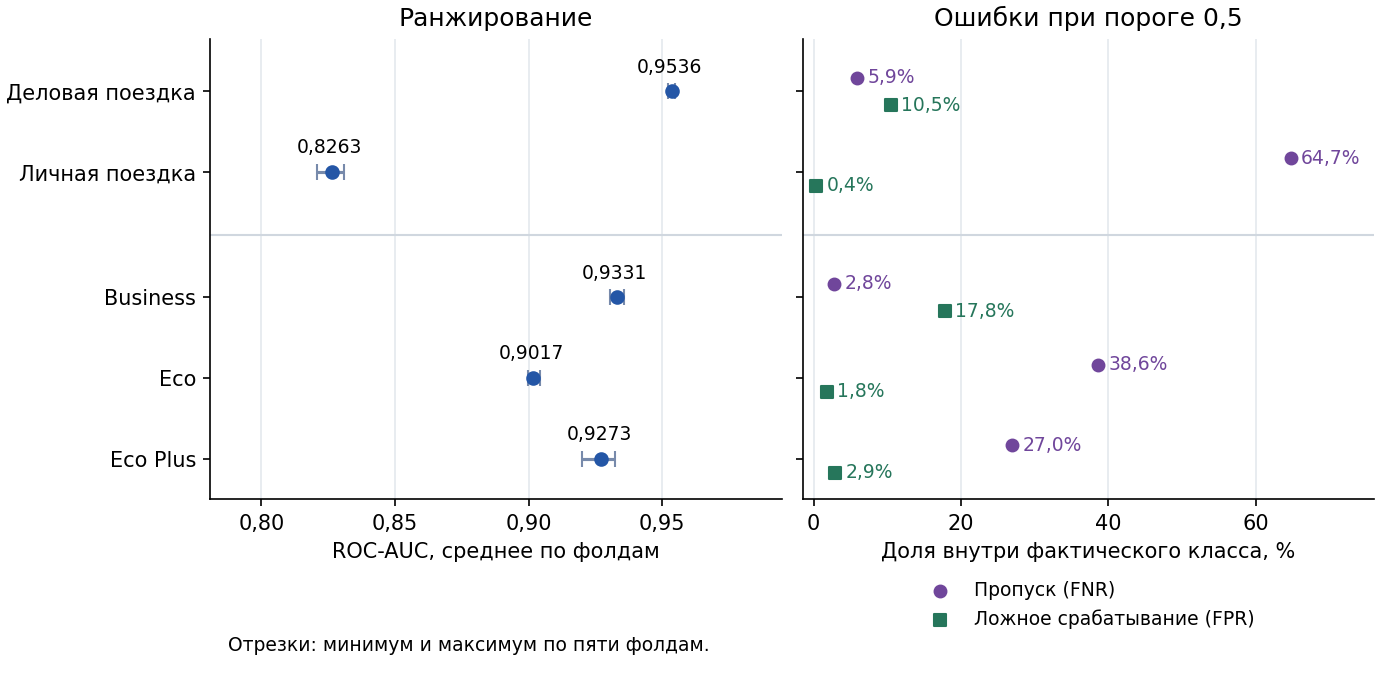

Группа,Строк,Ответы + / −,ROC-AUC,OOF ROC-AUC,FN / +,FP / −
Деловая,497 441,290 673 / 206 768,"0,95355","0,95354",17 229 / 290 673,21 661 / 206 768
Личная,202 194,19 666 / 182 528,"0,82634","0,82618",12 731 / 19 666,661 / 182 528
Business,342 212,248 210 / 94 002,"0,93306","0,93303",6 829 / 248 210,16 710 / 94 002
Eco,327 404,54 859 / 272 545,"0,90167","0,90163",21 170 / 54 859,4 944 / 272 545
Eco Plus,30 019,7 270 / 22 749,"0,92727","0,92727",1 961 / 7 270,668 / 22 749


In [5]:
display(Image(filename=str(report / "slices.png"),
              alt="ROC-AUC и доли ошибок по типу поездки и классу. В личных поездках при пороге 0,5 доля пропусков 64,7%."))
slices = read("slices")
show(pd.DataFrame({
    "Группа": slices.group,
    "Строк": slices.n,
    "Ответы + / −": [fraction(p, n) for p, n in zip(slices.positive, slices.negative)],
    "ROC-AUC": slices.mean_fold_auc,
    "OOF ROC-AUC": slices.pooled_oof_auc,
    "FN / +": [fraction(fn, total) for fn, total in zip(slices.fn, slices.positive)],
    "FP / −": [fraction(fp, total) for fp, total in zip(slices.fp, slices.negative)],
}), {"ROC-AUC": "{:.5f}", "OOF ROC-AUC": "{:.5f}"})

- **Поездки.** При пороге 0,5 модель пропускает 64,7% положительных ответов в личных поездках и 5,9% в деловых. Ложных срабатываний при этом меньше в личных поездках. Долю пропусков считаем от положительных ответов, долю ложных срабатываний от отрицательных.
- **Классы.** ROC-AUC ниже всего в Eco. У меньшего по размеру Eco Plus самый широкий разброс между фолдами среди классов обслуживания. Тип поездки и класс пересекаются, поэтому выводы по каждому срезу описательные.

## Устойчивость

| Проверка | Меняем | Сохраняем |
|---|---|---|
| Новое разбиение | Seed разбиения 42, 13, 73 | Полный объём обучающей части, модель и её seed 42 |
| Меньше данных | 100%, 50%, 20% обучающих строк исходного фолда | Те же проверочные строки и настройки модели |

Подвыборки 20% и 50% вложены и стратифицированы. Их выбираем с seed `20261124`, сохраняем исходный порядок строк и переобучаем всю цепочку предобработки и модели.

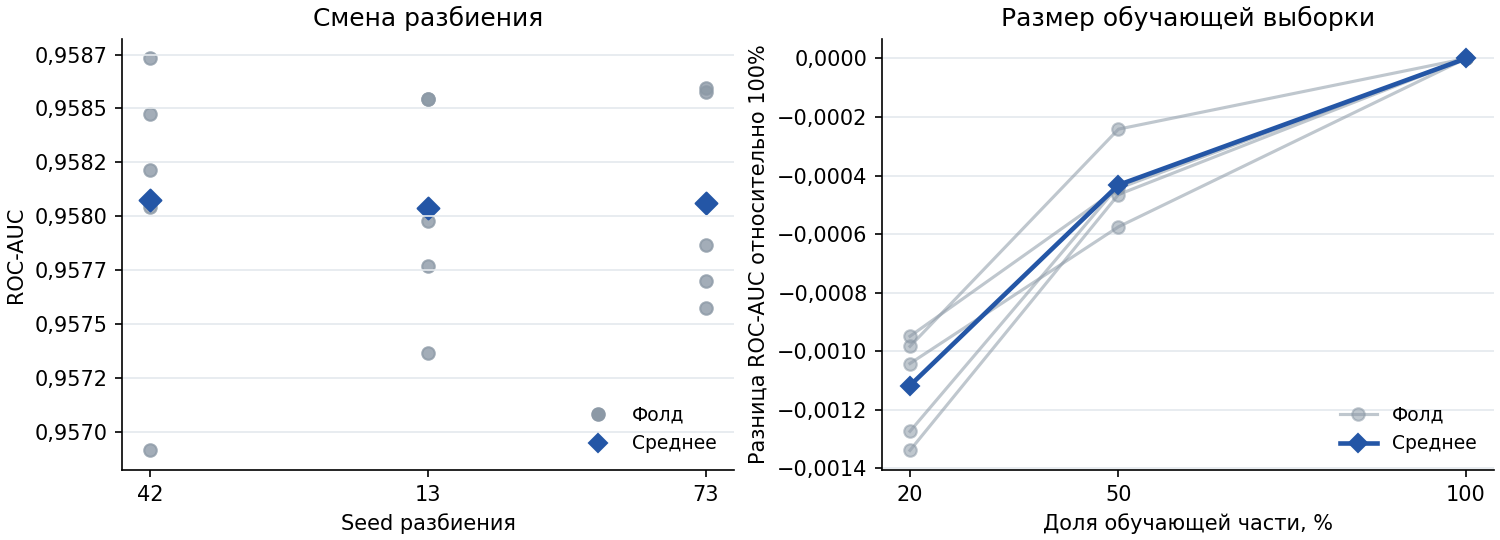

Seed разбиения,ROC-AUC,Мин. фолд,Макс. фолд
42,"0,958076","0,956913","0,958732"
13,"0,958040","0,957365","0,958546"
73,"0,958062","0,957575","0,958597"


Доля обучения,Строк на фолд,ROC-AUC,Средняя разница,Размах разниц
100%,559 708,"0,958076","0,000000","+0,000000 … +0,000000"
50%,279 854,"0,957643","-0,000432","−0,000575 … −0,000241"
20%,111 941,"0,956958","-0,001118","−0,001339 … −0,000949"


In [6]:
display(Image(filename=str(report / "robustness.png"),
              alt="ROC-AUC почти совпадает при смене seed и снижается на всех фолдах при сокращении обучающих данных."))
folds = read("robustness_folds")
by_seed = (folds[folds.train_fraction == 1].groupby("split_seed", sort=False)
           .roc_auc.agg(["mean", "min", "max"]).reset_index())
by_seed.columns = ["Seed разбиения", "ROC-AUC", "Мин. фолд", "Макс. фолд"]
show(by_seed, {column: "{:.6f}" for column in by_seed.columns[1:]})

by_size = (folds[folds.split_seed == 42].groupby("train_fraction", sort=False)
           .agg(rows=("n_train", "min"), auc=("roc_auc", "mean"), delta=("delta_vs_full", "mean"),
                low=("delta_vs_full", "min"), high=("delta_vs_full", "max")).reset_index())
by_size["Доля обучения"] = by_size.train_fraction.map(lambda f: f"{f:.0%}")
by_size["Размах разниц"] = [
    f"{low:+.6f} … {high:+.6f}".replace(".", ",").replace("-", "−")
    for low, high in zip(by_size.low, by_size.high)
]
by_size = by_size.rename(columns={"rows": "Строк на фолд", "auc": "ROC-AUC", "delta": "Средняя разница"})
show(by_size[["Доля обучения", "Строк на фолд", "ROC-AUC", "Средняя разница", "Размах разниц"]],
     {"ROC-AUC": "{:.6f}", "Средняя разница": "{:.6f}"})

- **Разбиение.** Средние лежат между **0,958040** и **0,958076**. Фолды разных разбиений содержат разные строки, поэтому сравниваем средние по разбиениям.
- **Объём обучения.** На тех же проверочных строках среднее снизилось на **0,000432** при 50% обучающей части и на **0,001118** при 20%. Снижение есть во всех пяти исходных фолдах при обеих долях.

График показывает разброс наблюдений. Обучающие части пересекаются, а сокращение проверили на одном наборе вложенных подвыборок для каждого фолда.

## Границы применения

| Что увидели | Что проверить перед применением |
|---|---|
| При пороге 0,5 много пропусков в личных поездках | Качество внутри нужных групп и цену пропусков и ложных срабатываний |
| Оба теста устойчивости выполнены на одном синтетическом наборе | Переносимость на независимых данных целевой авиакомпании |
| Оценки услуг могут появляться после рейса или вместе с итоговым ответом | Доступность каждого признака к моменту прогноза |

Ошибки разметки и причины отдельных ответов потребуют дополнительных данных.

## Воспроизведение

Ноутбук читает опубликованные таблицы и графики. Команда `python -m src.diagnose_hw3 --check` сравнивает пересчитанные таблицы с опубликованными. [Данные, зависимости и команды запуска](../README.md#дз-3-ошибки-и-устойчивость-e3)